# QoE contínuo × QoE pós-vídeo

## 1. Configuração

In [1]:
import os
import re
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor

DATA_ROOT = "."

QOEC_DIR = os.path.join(DATA_ROOT, "QoE_Annotation_Data", "Continuous_QoE_Score")
QOEP_DIR = os.path.join(DATA_ROOT, "QoE_Annotation_Data", "Post_Video_QoE_Score")

def extract_pv(filename):
    m = re.search(r'[Pp](\d+)_[Vv](\d+)', os.path.basename(filename))
    if not m:
        raise ValueError(f"Não consegui extrair P/V de: {filename}")
    return int(m.group(1)), int(m.group(2))

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 2. QoE contínuo

In [2]:
dfs = []
for arquivo in glob.glob(os.path.join(QOEC_DIR, "RCQoE_*.txt")):
    participante, video = extract_pv(arquivo)
    df = pd.read_csv(arquivo, sep=';', usecols=[0, 1, 2])
    df.columns = ['ID', 'TimeStamp', 'RCQoE']
    df['Participante'] = participante
    df['Video'] = video
    dfs.append(df)

qoec = pd.concat(dfs, ignore_index=True).sort_values(['Participante', 'Video', 'ID'])
qoec = qoec.reset_index(drop=True)

print(qoec.shape)
qoec.head()

(149185, 5)


,ID,TimeStamp,RCQoE,Participante,Video
0,0,1.433739e+10,0.0,1,1
1,1,1.433749e+10,0.0,1,1
2,2,1.433759e+10,0.0,1,1
3,3,1.433769e+10,0.0,1,1
4,4,1.433779e+10,0.0,1,1


In [3]:
qoec['RCQoE'].describe()

count    149185.000000
mean          0.400326
std           0.296072
min           0.000000
25%           0.071447
50%           0.434678
75%           0.639027
max           0.999671
Name: RCQoE, dtype: float64

Podemos observar que o valor mínimo do Score de QoE contínuo é zero, sendo que o esperado seria -1. 

In [1]:
# qual é a média de entradas por participante e por vídeo?
media_entradas = qoec.groupby(['Participante', 'Video']).size().mean()
print(f"Média de entradas por participante e vídeo: {media_entradas:.2f}")

NameError: name 'qoec' is not defined

## 3. QoE pós-vídeo

In [4]:
registros = []
for arquivo in glob.glob(os.path.join(QOEP_DIR, "PostQuestion_*.txt")):
    participante, video = extract_pv(arquivo)
    linhas = open(arquivo).read().splitlines()
    registros.append({
        'Participante': participante,
        'Video': video,
        'MOS': int(linhas[1].split(';')[2]),
    })

qoep = pd.DataFrame(registros).sort_values(['Participante', 'Video']).reset_index(drop=True)

print(qoep.shape)
qoep['MOS'].value_counts().sort_index()

(1280, 3)


MOS
1    100
2    238
3    473
4    347
5    122
Name: count, dtype: int64

In [ ]:
# histograma do MOS
plt.hist(qoep['MOS'], bins=np.arange(1, 7) - 0.5, edgecolor='black')
plt.xticks(range(1, 6))

In [ ]:
# qual é a média de MOS por participante e por vídeo?
media_mos = qoep.groupby(['Participante', 'Video'])['MOS'].mean().mean()
print(f"Média de MOS por participante e vídeo: {media_mos:.2f}")

## 4. Integridade das séries

sessões: 1280
comprimento min/mediana/max: 78 117.0 119
amostras exatamente zero: 21.0%
zeros iniciais (mediana): 22.0
séries constantes: 47


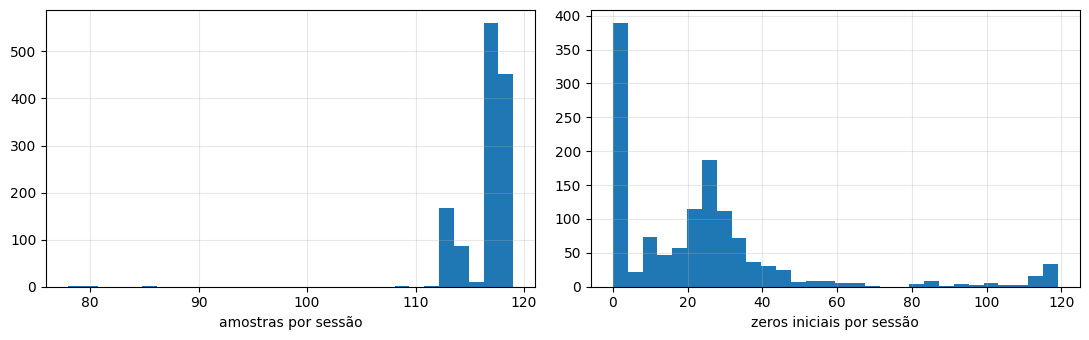

In [ ]:
comprimentos = qoec.groupby(['Participante', 'Video'])['ID'].size()
zeros_iniciais = qoec.groupby(['Participante', 'Video'])['RCQoE'].apply(
    lambda s: int(np.argmax(s.values != 0)) if (s.values != 0).any() else len(s)
)
serie_nula = qoec.groupby(['Participante', 'Video'])['RCQoE'].std() == 0

print("sessões:", len(comprimentos))
print("comprimento min/mediana/max:", comprimentos.min(), comprimentos.median(), comprimentos.max())
print("amostras exatamente zero: %.1f%%" % (100 * (qoec['RCQoE'] == 0).mean()))
print("zeros iniciais (mediana):", zeros_iniciais.median())
print("séries zeradas:", int(serie_nula.sum()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(comprimentos, bins=30)
ax[0].set_xlabel("amostras por sessão")
ax[1].hist(zeros_iniciais, bins=30)
ax[1].set_xlabel("zeros iniciais por sessão")
plt.tight_layout()
plt.show()

Como cada vídeo tem 30s e no QoE contínuo a frequência da resposta é 10 Hz, então deveríamos ter em torno de 300 amostras no vídeo inteiro. Porem a média de amostras por vídeo na maioria das sessões é de 117.

- Uma hipótese pode ser que os participantes tinham um delay e então valores repetidos em sequência foram excluídos. Não sei, preciso olhar o artigo

47 sessões são inteiramente constantes (quase todas zeradas). São participantes que não mexeram no touchpad naquele vídeo e ainda assim deram MOS 4 ou 5

In [ ]:
# quem são os participantes que mais zeraram a série?
participantes_mais_zeros = qoec[qoec['RCQoE'] == 0].groupby('Participante').size().sort_values(ascending=False)
print(participantes_mais_zeros)

In [ ]:
# quais vídeos tiveram mais zeros?
videos_mais_zeros = qoec[qoec['RCQoE'] == 0].groupby('Video').size().sort_values(ascending=False)
print(videos_mais_zeros)

## 5. Reamostragem para comprimento fixo

In [6]:
T = 100
chaves, curvas = [], []

for (participante, video), d in qoec.groupby(['Participante', 'Video']):
    s = d['RCQoE'].values
    curvas.append(np.interp(np.linspace(0, 1, T), np.linspace(0, 1, len(s)), s))
    chaves.append((participante, video))

curvas = np.array(curvas)
chaves = pd.DataFrame(chaves, columns=['Participante', 'Video'])

print(curvas.shape)

(1280, 100)


## 6. Agregados por sessão

In [ ]:
sessoes = chaves.copy()
sessoes['media'] = curvas.mean(axis=1)
sessoes['mediana'] = np.median(curvas, axis=1)
sessoes['desvio'] = curvas.std(axis=1)
sessoes['minimo'] = curvas.min(axis=1)
sessoes['maximo'] = curvas.max(axis=1)
sessoes['final'] = curvas[:, -1] # o último valor da série reamostrada, ou seja, a nota contínua que o participante estava marcando no instante final do vídeo.
sessoes['final_10'] = curvas[:, -10:].mean(axis=1) # a média dos últimos 10 pontos (últimos 10% do vídeo).
sessoes['frac_zeros'] = (curvas == 0).mean(axis=1)

base = sessoes.merge(qoep, on=['Participante', 'Video'])

print(base.shape)
base.head()

(1280, 11)


,Participante,Video,media,mediana,desvio,minimo,maximo,final,final_10,frac_zeros,MOS
0,1,1,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,1.00,5
1,1,2,0.493446,0.652483,0.270594,0.0,0.658464,0.656531,0.655716,0.23,5
2,1,3,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,1.00,4
3,1,4,0.101917,0.073712,0.113958,0.0,0.374535,0.168505,0.167217,0.50,1
4,1,5,0.372172,0.272914,0.229100,0.0,0.902727,0.272590,0.256409,0.06,2


## 7. Distribuições

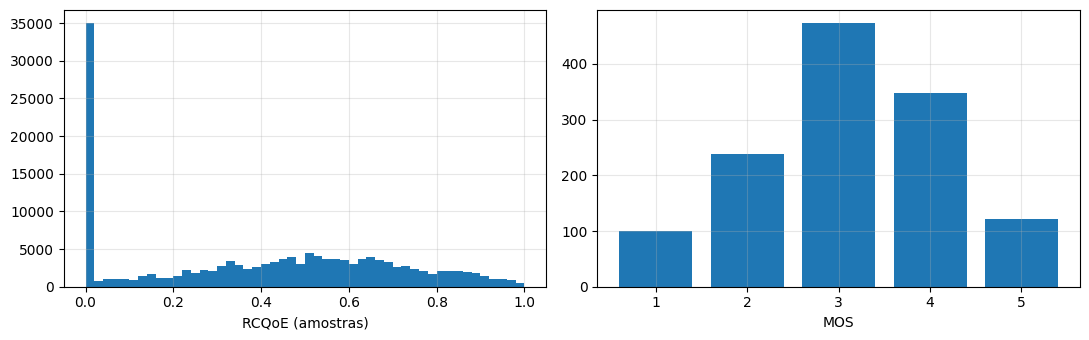

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(qoec['RCQoE'], bins=50)
ax[0].set_xlabel("RCQoE (amostras)")
ax[1].bar(base['MOS'].value_counts().sort_index().index,
          base['MOS'].value_counts().sort_index().values)
ax[1].set_xlabel("MOS")
plt.tight_layout()
plt.show()

In [ ]:
# gráfico de RCQoE sem considerar zeros iniciais
    

Vemos que para o RCQoE se concentra em maioria no zero. Isso seria equivalente a um MOS = 1, coisa que não vemos no gráfico de MOS. Se desconsiderássemos os zeros, vemos que a distribuição se assemelha mais ao QoE pós vídeo. 

## 8. Curva média de QoEC por nível de MOS

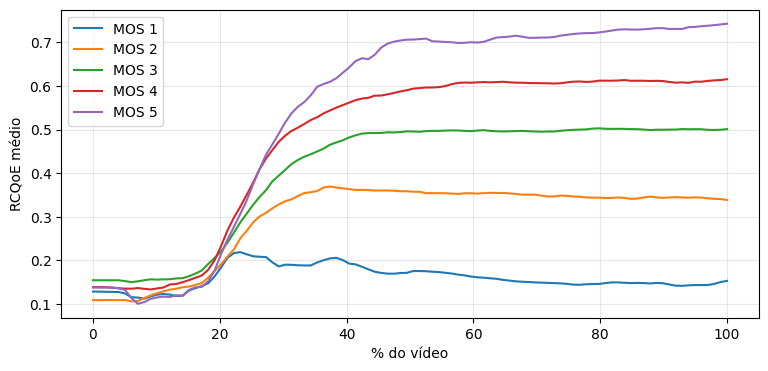

In [9]:
plt.figure()
for mos in sorted(base['MOS'].unique()):
    plt.plot(np.linspace(0, 100, T), curvas[(base['MOS'] == mos).values].mean(axis=0), label=f"MOS {mos}")
plt.xlabel("% do vídeo")
plt.ylabel("RCQoE médio")
plt.legend()
plt.show()

Mesmo com o problema de escala na classificação do RCQoE, vemos que a média do RCQoE atinge um platô próximo à metade do vídeo. E de fato, quanto menor o MOS, menor a média do RCQoE. 

In [ ]:
# dividir valores possíveis de RCQoE em partes iguais e ver a qual MOS ele seria relacionado? 

## 9. Agregados de QoEC contra MOS

In [10]:
metricas = ['media', 'mediana', 'desvio', 'minimo', 'maximo', 'final', 'final_10', 'frac_zeros']

correl = pd.DataFrame({
    'pearson': [pearsonr(base[m], base['MOS'])[0] for m in metricas],
    'spearman': [spearmanr(base[m], base['MOS'])[0] for m in metricas],
}, index=metricas).round(3)

correl.sort_values('spearman', ascending=False)

,pearson,spearman
final,0.609,0.614
final_10,0.603,0.606
mediana,0.536,0.545
media,0.509,0.514
maximo,0.440,0.487
desvio,0.375,0.387
minimo,0.061,0.007
frac_zeros,-0.019,-0.011


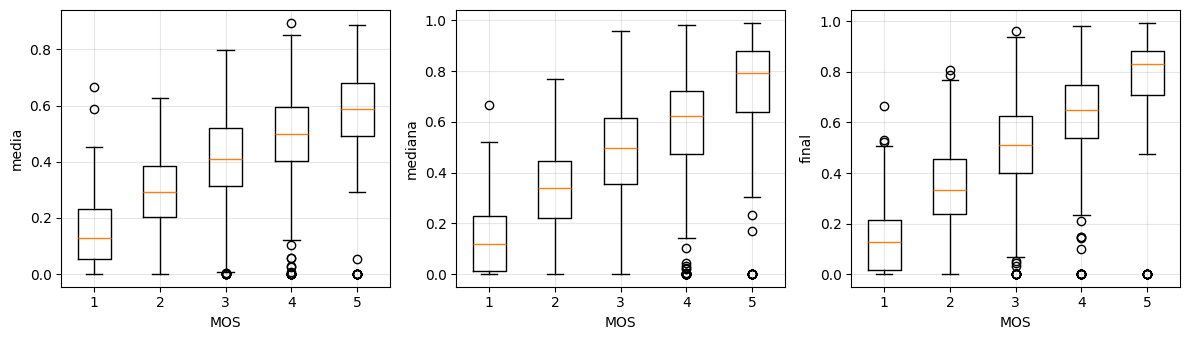

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
for eixo, m in zip(ax, ['media RCQoE', 'mediana RCQoE', 'final RCQoE']):
    eixo.boxplot([base.loc[base['MOS'] == k, m] for k in sorted(base['MOS'].unique())],
                 tick_labels=sorted(base['MOS'].unique()))
    eixo.set_xlabel("MOS")
    eixo.set_ylabel(m)
plt.tight_layout()
plt.show()

Vemos pelos boxplots que os valores de média, mediana e valor final do RCQoE está alinhado com o valor 

In [12]:
base.groupby('MOS')[metricas].mean().round(3)

,media,mediana,desvio,minimo,maximo,final,final_10,frac_zeros
MOS,,,,,,,,
1,0.160,0.152,0.100,0.038,0.399,0.153,0.145,0.239
2,0.298,0.323,0.146,0.068,0.510,0.339,0.343,0.225
3,0.407,0.467,0.181,0.113,0.616,0.501,0.500,0.185
4,0.480,0.570,0.223,0.102,0.705,0.616,0.611,0.205
5,0.547,0.693,0.271,0.075,0.785,0.743,0.736,0.229


## 10. Conjunto de modelagem

In [13]:
X_seq = curvas
X_agg = base[metricas].values
y = base['MOS'].values.astype(float)
grupos = base['Participante'].values

print(X_seq.shape, X_agg.shape, y.shape)

(1280, 100) (1280, 8) (1280,)


## 11. Divisão por participante
Melhor forma de divisão nesse caso, pois se fizermos aleatoriamente o mesmo participante poderia cair no treino e no teste

In [14]:
treino, teste = next(
    GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42).split(X_seq, y, grupos)
)

print("treino:", len(treino), "| teste:", len(teste))
print("participantes em teste:", sorted(set(grupos[teste])))
print("sobreposição:", set(grupos[treino]) & set(grupos[teste]))

treino: 960 | teste: 320
participantes em teste: [np.int64(9), np.int64(10), np.int64(16), np.int64(18), np.int64(25), np.int64(26), np.int64(30), np.int64(31)]
sobreposição: set()


## 12. Avaliação

In [15]:
resultados = []

def avaliar(nome, y_pred):
    constante = y_pred.min() == y_pred.max()
    resultados.append({
        'modelo': nome,
        'RMSE': np.sqrt(np.mean((y[teste] - y_pred) ** 2)),
        'MAE': np.mean(np.abs(y[teste] - y_pred)),
        'PLCC': np.nan if constante else pearsonr(y[teste], y_pred)[0],
        'SRCC': np.nan if constante else spearmanr(y[teste], y_pred)[0],
    })
    return pd.DataFrame(resultados).set_index('modelo').round(3)

## 13. Referências de comparação

In [16]:
avaliar("média do treino", np.full(len(teste), y[treino].mean()))

ridge_seq = make_pipeline(StandardScaler(), Ridge()).fit(X_seq[treino], y[treino])
avaliar("ridge (sequência)", ridge_seq.predict(X_seq[teste]))

ridge_agg = make_pipeline(StandardScaler(), Ridge()).fit(X_agg[treino], y[treino])
avaliar("ridge (agregados)", ridge_agg.predict(X_agg[teste]))

,RMSE,MAE,PLCC,SRCC
modelo,,,,
média do treino,1.067,0.828,NaN,NaN
ridge (sequência),0.841,0.675,0.616,0.60
ridge (agregados),0.796,0.627,0.665,0.62


## 14. Rede neural sobre a sequência de QoEC

In [17]:
mlp_seq = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(128, 64), max_iter=1500,
                 early_stopping=True, random_state=42),
).fit(X_seq[treino], y[treino])

avaliar("MLP (sequência)", mlp_seq.predict(X_seq[teste]))

,RMSE,MAE,PLCC,SRCC
modelo,,,,
média do treino,1.067,0.828,NaN,NaN
ridge (sequência),0.841,0.675,0.616,0.600
ridge (agregados),0.796,0.627,0.665,0.620
MLP (sequência),0.859,0.695,0.613,0.617


## 15. Rede neural sobre os agregados de QoEC

In [18]:
mlp_agg = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000,
                 early_stopping=True, random_state=42),
).fit(X_agg[treino], y[treino])

avaliar("MLP (agregados)", mlp_agg.predict(X_agg[teste]))

,RMSE,MAE,PLCC,SRCC
modelo,,,,
média do treino,1.067,0.828,NaN,NaN
ridge (sequência),0.841,0.675,0.616,0.600
ridge (agregados),0.796,0.627,0.665,0.620
MLP (sequência),0.859,0.695,0.613,0.617
MLP (agregados),0.786,0.618,0.675,0.645


## 16. Comparação

In [19]:
pd.DataFrame(resultados).set_index('modelo').round(3).sort_values('RMSE')

,RMSE,MAE,PLCC,SRCC
modelo,,,,
MLP (agregados),0.786,0.618,0.675,0.645
ridge (agregados),0.796,0.627,0.665,0.620
ridge (sequência),0.841,0.675,0.616,0.600
MLP (sequência),0.859,0.695,0.613,0.617
média do treino,1.067,0.828,NaN,NaN


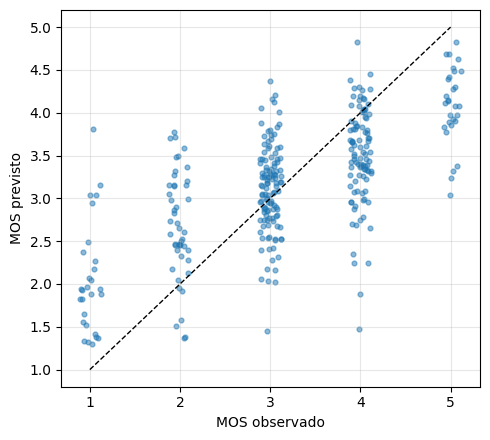

In [20]:
y_pred = mlp_agg.predict(X_agg[teste])

plt.figure(figsize=(5, 4.5))
plt.scatter(y[teste] + np.random.uniform(-0.12, 0.12, len(teste)), y_pred, s=12, alpha=0.5)
plt.plot([1, 5], [1, 5], 'k--', lw=1)
plt.xlabel("MOS observado")
plt.ylabel("MOS previsto")
plt.tight_layout()
plt.show()